Import all the necessary libraries.

In [35]:
from bioio import BioImage          # for import of different formats (runs on bioformats)
import numpy as np                  # for mathematical operations
import napari                       # image viewer
import skimage                      # for operation with images, such as filtering or binary operations
import matplotlib.pyplot as plt     # for plotting

# Load data
Load data and show some information. 

In [36]:
filepath = r"C:\Users\sveco\Downloads\OneDrive_2026-01-15\Pics for Sholl analysis\20xWT2-29-4-25--ibaab5076_2025-05-05_Protocol 6_11.16.44_F05.ims"

img = BioImage(filepath)
raw = img.get_image_data().squeeze()    # squeeze removes the first dimension corresponding to time-points, as there is only one time point

print(img.metadata.images[0].pixels.physical_size_x)   # This shows the physical pixel size - depends on objective mag used

mip_both = np.max(raw, axis=1)
mip_green = mip_both[1]
print(mip_green.shape)    # Shows the number of pixels in the MIP image

0.6091666666666689
(1992, 2040)


# Image segmentation
## Preprocess green channel, binarize and convert to skeletons
Perform filtering on the green channel to supress noise, enhance contrast and remove bright debris.

In [37]:
blurred = skimage.filters.gaussian(mip_green, sigma=15, preserve_range=True)
dog = mip_green - blurred   # Difference of Gaussians, removes the background
median = skimage.filters.median(dog)    # Median filter to reduce noise
sharpened = skimage.filters.unsharp_mask(median, radius=1, amount=0.5, preserve_range=True) # Sharpening

debris_mask = sharpened > 2000
sharpened[debris_mask] = 0

viewer = napari.Viewer()
viewer.add_image(mip_green, name='MIP')
viewer.add_image(sharpened, name='Sharpened MIP')

<Image layer 'Sharpened MIP' at 0x28a1dd02200>

Find threshold using one of the automatic algorithms, binarize the image, clean up using erosion and dilation and then skeletonize.

In [38]:
threshold = skimage.filters.threshold_li(sharpened)
# threshold = skimage.filters.threshold_isodata(sharpened)  # Alternative thresholding returning more extensive masks
thresholded = sharpened > threshold
viewer.add_image(thresholded, name='Thresholded Sharpened MIP', blending='additive', opacity=0.3)

struct_elem = skimage.morphology.disk(2)        # this defines the extend of binary operations
dilated = skimage.morphology.binary_dilation(thresholded, struct_elem)
eroded = skimage.morphology.binary_erosion(dilated, struct_elem)

viewer.add_image(eroded, name='Dilate-Erode Thresholded MIP', blending='additive', opacity=0.3)

skeleton = skimage.morphology.skeletonize(eroded)
viewer.add_image(skeleton, name='Skeletonized Eroded MIP', blending='additive', opacity=0.9)

<Image layer 'Skeletonized Eroded MIP' at 0x289c313fbb0>

## Extract somas and get astrocyte centers
Get mask of soma from the blurred green channel.

In [39]:
viewer = napari.Viewer()

viewer.add_image(mip_green, name='second channel MIP', blending='additive')

blurred_less = skimage.filters.gaussian(mip_green, sigma=4, preserve_range=True)
blurred_more = skimage.filters.gaussian(mip_green, sigma=10, preserve_range=True)
soma = blurred_less - blurred_more

debris_mask = soma > 400
soma[debris_mask] = 0

threshold_soma = skimage.filters.threshold_triangle(soma)
soma_binary = soma > threshold_soma
viewer.add_image(soma_binary, name='soma binary', blending='additive', opacity=0.5)

struct_elem = skimage.morphology.disk(2)
eroded = skimage.morphology.binary_erosion(soma_binary, struct_elem)
viewer.add_image(eroded, name='Eroded Nuclei Binary', blending='additive', opacity=0.5, colormap='magenta')

<Image layer 'Eroded Nuclei Binary' at 0x28a182925f0>

Get mask of nuclei (not perfectly separated) from the DAPI channel. Not all nuclei belong to astrocytes (which are relevant for us).

In [40]:
nuclei_mip = mip_both[0]
viewer.add_image(nuclei_mip, name='Nuclei MIP', blending='additive')

median = skimage.filters.rank.median(nuclei_mip, skimage.morphology.disk(2))

threshold_nuclei = skimage.filters.threshold_triangle(median)
nuclei_binary = median > threshold_nuclei
viewer.add_image(nuclei_binary, name='Nuclei Binary', blending='additive', opacity=0.5)

c:\Users\sveco\miniforge3\envs\analysisPythonEnv\lib\site-packages\skimage\filters\rank\generic.py:332: UserWarning: Bad rank filter performance is expected due to a large number of bins (5916), equivalent to an approximate bitdepth of 12.5.
  image, footprint, out, mask, n_bins = _preprocess_input(


<Image layer 'Nuclei Binary' at 0x289f69aa650>

Combine the two masks to get only positive areas in both channels using the AND operation.

In [41]:
combined = eroded & nuclei_binary
viewer.add_image(combined, name='Combined Soma and Nuclei Binary', blending='additive', opacity=0.5, colormap='cyan')

<Image layer 'Combined Soma and Nuclei Binary' at 0x289f69aa470>

Extract centroids of the soma areas (we set a size limit on the areas we want to consider).

In [42]:
size_limit = 5
labels = skimage.measure.label(combined, connectivity=2)

props = skimage.measure.regionprops(labels)
centroids = [prop.centroid for prop in props if prop.area > size_limit]
viewer.add_points(centroids, size=5, face_color='red')

<Points layer 'Points' at 0x28a317f34f0>

Create circles of defined radius around the centroid points.

In [43]:
radius = 7
offsets = np.array([[-radius, 0], [0, radius], [radius, 0], [0, -radius]])
circles = [np.array([[cy + dy, cx + dx] for dy, dx in offsets]) for cy, cx in centroids]
print(circles)

viewer.add_shapes(circles, shape_type='ellipse', face_color='transparent', edge_color='red')

[array([[-6.15, 42.2 ],
       [ 0.85, 49.2 ],
       [ 7.85, 42.2 ],
       [ 0.85, 35.2 ]]), array([[ -6.06666667, 221.13333333],
       [  0.93333333, 228.13333333],
       [  7.93333333, 221.13333333],
       [  0.93333333, 214.13333333]]), array([[ -4.49019608, 582.29411765],
       [  2.50980392, 589.29411765],
       [  9.50980392, 582.29411765],
       [  2.50980392, 575.29411765]]), array([[-5.77272727e+00,  1.23440909e+03],
       [ 1.22727273e+00,  1.24140909e+03],
       [ 8.22727273e+00,  1.23440909e+03],
       [ 1.22727273e+00,  1.22740909e+03]]), array([[  1.93220339, 965.54237288],
       [  8.93220339, 972.54237288],
       [ 15.93220339, 965.54237288],
       [  8.93220339, 958.54237288]]), array([[  10.7029703, 1105.9009901],
       [  17.7029703, 1112.9009901],
       [  24.7029703, 1105.9009901],
       [  17.7029703, 1098.9009901]]), array([[  8.92307692, 256.33333333],
       [ 15.92307692, 263.33333333],
       [ 22.92307692, 256.33333333],
       [ 15.92307692

<Shapes layer 'circles' at 0x28a0b10ab90>

## Filter only valid skeletons and soma
Filter the skeletons to keep only the ones that overlap with the identified soma areas.

In [44]:
labels_skeleton = skimage.measure.label(skeleton, connectivity=2)
overlapping_labels = np.unique(labels_skeleton[(labels_skeleton > 0) & combined])
filtered_skeleton = np.isin(labels_skeleton, overlapping_labels)

Filter the circles to keep only one (with the highest mean intensity) per skeleton.

In [45]:
best_circle_for_label = {}
circle_mean_intensities = np.full(len(circles), np.nan, dtype=float)
circle_overlaps = [tuple() for _ in circles]

for idx, coords in enumerate(circles):
    rr, cc = skimage.draw.polygon(coords[:, 0], coords[:, 1], shape=mip_green.shape)
    if rr.size == 0:
        continue

    mean_intensity = float(np.mean(mip_green[rr, cc]))
    circle_mean_intensities[idx] = mean_intensity

    overlapping = np.unique(labels_skeleton[rr, cc])
    overlapping = overlapping[overlapping > 0]
    circle_overlaps[idx] = tuple(int(label) for label in overlapping)

    if overlapping.size == 0:
        continue

    for label_id in overlapping:
        previous = best_circle_for_label.get(label_id)
        if previous is None or mean_intensity > previous["mean_intensity"]:
            best_circle_for_label[label_id] = {
                "circle_index": idx,
                "mean_intensity": mean_intensity,
            }

selected_circle_indices = {label: data["circle_index"] for label, data in best_circle_for_label.items()}
selected_circle_polygons = {label: circles[index] for label, index in selected_circle_indices.items()}

best_circle_polygons = list(selected_circle_polygons.values())
if best_circle_polygons:
    viewer.add_shapes(
        best_circle_polygons,
        shape_type='ellipse',
        face_color='transparent',
        edge_color='orange',
        edge_width=2,
        name='Best Circles',
    )

# Sholl analysis
Sholl analysis: Calculate the number of intersection of the skeleton with concentric circle layers.

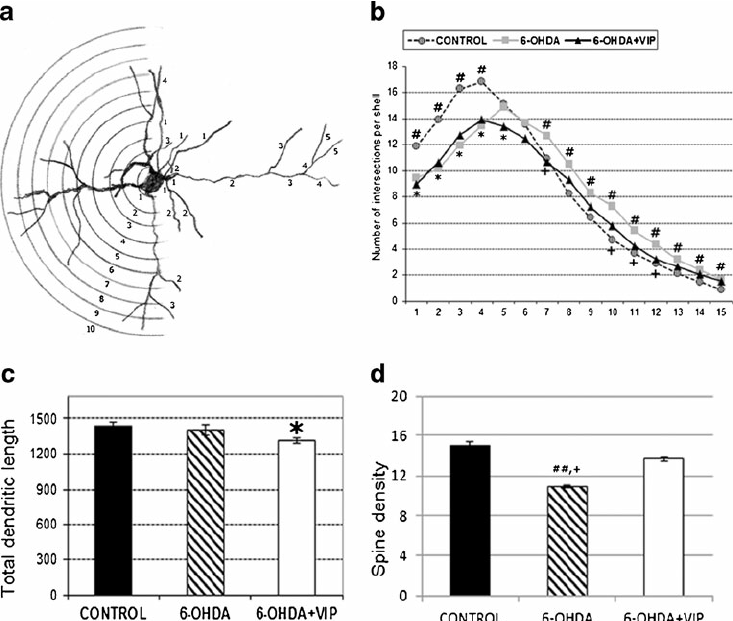
https://www.google.com/url?sa=t&source=web&rct=j&url=https%3A%2F%2Fwww.researchgate.net%2Ffigure%2FSchematic-representation-of-Sholl-analysis-method-in-the-camera-lucida-drawing-of-an-MSN_fig1_235968780&ved=0CBYQjRxqGAoTCLCMmZffrJIDFQAAAAAdAAAAABCNAg&opi=89978449

In [46]:
sholl_step = 2

skeleton_props = {prop.label: prop for prop in skimage.measure.regionprops(labels_skeleton)}

sholl_counts = []

for label_id, polygon in selected_circle_polygons.items():
    label_int = int(label_id)
    prop = skeleton_props.get(label_int)
    if prop is None or polygon.size == 0:
        continue

    center = polygon.mean(axis=0)
    coords = prop.coords
    if coords.size == 0:
        continue

    distances = np.linalg.norm(coords - center, axis=1)
    max_radius = float(distances.max())
    if not np.isfinite(max_radius) or max_radius <= radius:
        continue

    radius_edges = np.arange(radius, max_radius + sholl_step, sholl_step, dtype=float)
    intersection_counts = []

    min_row, min_col, max_row, max_col = prop.bbox
    bbox_origin = np.array([min_row, min_col])

    for r_inner in radius_edges:
        ring_mask = (distances >= r_inner) & (distances < r_inner + sholl_step)
        if not np.any(ring_mask):
            intersection_counts.append(0)
            continue

        ring_coords = coords[ring_mask] - bbox_origin
        ring_image = np.zeros_like(prop.image, dtype=bool)
        ring_image[ring_coords[:, 0], ring_coords[:, 1]] = True

        ring_labels = skimage.measure.label(ring_image, connectivity=2)
        intersection_counts.append(int(ring_labels.max()))

    sholl_counts.append(intersection_counts)

max_length = max(len(counts) for counts in sholl_counts)
sholl_matrix = np.vstack([
    np.pad(np.asarray(a, dtype=float), (0, max_length - len(a)), constant_values=np.nan)
    for a in sholl_counts
])

layers = np.arange(radius, max_length + sholl_step, sholl_step, dtype=float)

Plot the average number of branches by distance from the centroid.

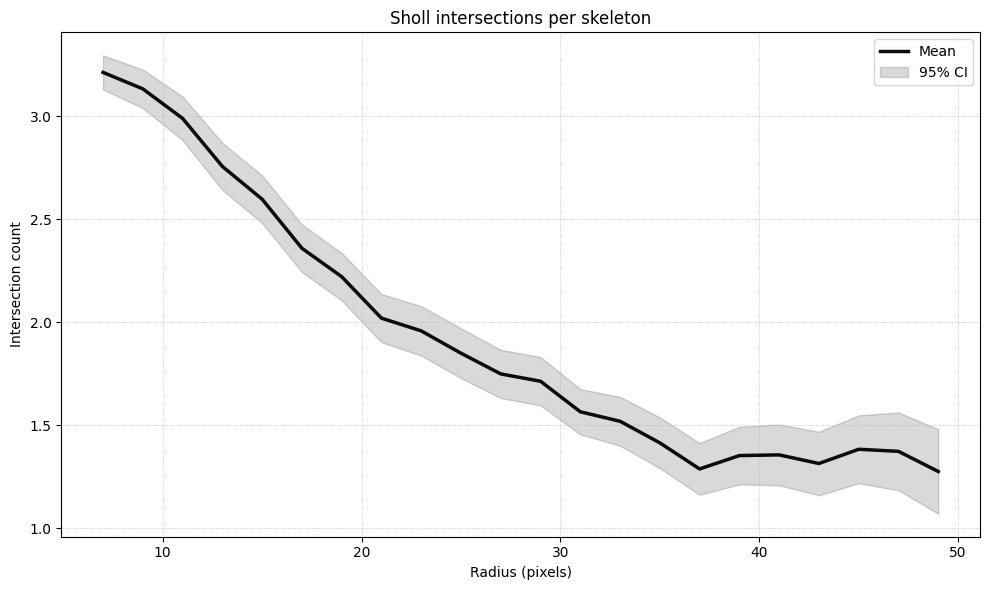

In [47]:
fig, ax = plt.subplots(figsize=(10, 6))

if sholl_matrix.size == 0 or layers.size == 0:
    ax.text(0.5, 0.5, "No Sholl data available", ha="center", va="center", transform=ax.transAxes)
    ax.axis("off")
    plt.show()
else:
    n_cols = sholl_matrix.shape[1]
    n_samples = min(n_cols, layers.size)
    radii = layers[:n_samples]
    data = sholl_matrix[:, :n_samples]

    valid = np.isfinite(data)
    if not valid.any():
        ax.text(0.5, 0.5, "No finite Sholl data available", ha="center", va="center", transform=ax.transAxes)
        ax.axis("off")
        plt.show()
    else:
        mean_counts = np.nanmean(data, axis=0)
        sample_sizes = valid.sum(axis=0)
        stds = np.nanstd(data, axis=0, ddof=1)
        stds[sample_sizes <= 1] = 0.0

        sem = np.zeros_like(mean_counts)
        nonzero = sample_sizes > 0
        sem[nonzero] = stds[nonzero] / np.sqrt(sample_sizes[nonzero])
        ci_half_width = 1.96 * sem
        lower = mean_counts - ci_half_width
        upper = mean_counts + ci_half_width

        mean_line, = ax.plot(radii, mean_counts, color="black", linewidth=2.5, alpha=0.95, label="Mean")
        ci_band = ax.fill_between(radii, lower, upper, color="black", alpha=0.15, label="95% CI")

        ax.set_xlabel("Radius (pixels)")
        ax.set_ylabel("Intersection count")
        ax.set_title("Sholl intersections per skeleton")
        ax.grid(True, which="both", linestyle=":", linewidth=0.5)
        ax.legend([mean_line, ci_band], ["Mean", "95% CI"], loc="upper right")

        plt.tight_layout()
        plt.show()
